# Introduction to Quantitative Biology — Lecture 5
## Random walks and diffusion

*Luca Ciandrini — luca.ciandrini@umontpellier.fr*

Inside a cell nothing is carried where it has to go, with few exceptions. A transcription factor
made in one corner of a bacterium reaches its promoter by being knocked about by water molecules,
millions of times per second, in random directions. Today we ask:

1. **Sections 1-3.** What does a molecule that moves at random actually do? We build it from a coin
   flip, the same coin of the bootcamp and of the partitioning in Lecture 1.
2. **Section 4.** How far does it get, in real units? Why a bacterium can rely on diffusion and a
   neuron cannot.
3. **Section 5.** How long does a transcription factor take to find its site? This is the number
   that justified, in Lecture 2, treating the promoter as always at equilibrium.
4. **Section 6.** A bacterium swims, and it also moves at random. How can it still go *towards*
   food? This sets up the next lecture.

**Reading.** Phillips et al., *Physical Biology of the Cell*, Chapter 13 (in the course
resources): Sections 13.1, 13.2.1 and 13.3 follow what we do today.

**How to use it.** Before running a cell marked **PREDICT**, write down what you expect.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

BLUE, CORAL, INK, GREY = "#008AAE", "#F06E76", "#231F20", "#8399A3"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

---
## 1. A walker that flips a coin

### The model

A particle sits on a line of sites, a distance $a$ apart. Time goes in small steps $\Delta t$. At
each step:

| what the particle does | probability | displacement |
|---|---|---|
| jumps to the right | $k\,\Delta t$ | $+a$ |
| jumps to the left | $k\,\Delta t$ | $-a$ |
| stays where it is | $1 - 2k\,\Delta t$ | $0$ |

$k$ is a **rate**: jumps to the right per unit time. As in the stochastic simulation of Lecture 2,
the probability of an event in a short interval is the rate times the interval, so $\Delta t$ must
be small enough that $2k\,\Delta t < 1$.

Each step is independent of the previous ones: the particle has no memory of where it came from.
This is the whole model. (It is the model of PBoC Section 13.2.1, Figure 13.14.)

In [2]:
def random_walk(n_walkers, n_steps, k, dt, a, rng):
    '''Positions of n_walkers independent walkers, at times 0, dt, 2 dt, ..., n_steps dt.
    Returns an array with one row per walker and one column per time.'''
    # u[i, j] is a random number, uniform in [0, 1), attached to walker i at step j.
    # It is the "coin" that decides what that walker does at that step: the probability
    # that u falls in an interval is the length of the interval. So u < k dt happens with
    # probability k dt, and k dt <= u < 2 k dt also with probability k dt (see below).
    # Drawing all the numbers at once, instead of one at a time in a loop, is much faster.
    u = rng.random((n_walkers, n_steps))           # one random number per walker per step
    steps = np.zeros((n_walkers, n_steps))
    steps[u < k * dt] = +a                         # right, with probability k dt
    steps[(u >= k * dt) & (u < 2 * k * dt)] = -a   # left, with probability k dt
    # all the others stay at 0: the particle did not move
    # x[i, j] is the position of walker i after j steps (at time j dt). It has one more
    # column than steps: column 0 is the starting time, when nobody has moved yet.
    x = np.zeros((n_walkers, n_steps + 1))         # everybody starts at x = 0
    # np.cumsum(steps, axis=1) is a running total along each row (axis=1 = along time).
    # Example, one walker: steps = [+a, 0, -a, +a]  ->  cumsum = [a, a, 0, a].
    # The position after j steps is the sum of the first j displacements, so we store
    # these totals in columns 1, 2, ..., n_steps (x[:, 1:] = all rows, columns from 1 on).
    x[:, 1:] = np.cumsum(steps, axis=1)            # position = sum of the steps so far
    return x

The line `np.cumsum(steps, axis=1)` adds up the steps one after the other: the position after
$n$ steps is the sum of the first $n$ displacements. Everything that follows is about **the sum of
many independent random numbers**.

### One trajectory

We use $k = 1$, $\Delta t = 0.01$ (so each step the particle jumps with probability 0.02, and stays
with probability 0.98), and $a = 1$. Time and length are in units we have not chosen yet; Section 4
puts real units on them.

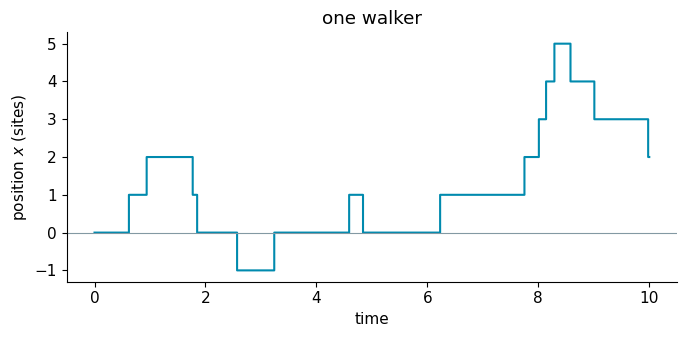

number of jumps: 16 in 1000 steps (expected 2 k t = 20)


In [3]:
k, dt, a = 1.0, 0.01, 1.0
n_steps = 1000                                     # total time 10
t = np.arange(n_steps + 1) * dt

rng = np.random.default_rng(1)
x_one = random_walk(1, n_steps, k, dt, a, rng)[0]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(t, x_one, where="post", color=BLUE, lw=1.5)
ax.axhline(0, color=GREY, lw=0.8)
ax.set(xlabel="time", ylabel="position $x$ (sites)", title="one walker")
plt.tight_layout(); plt.show()
print(f"number of jumps: {np.count_nonzero(np.diff(x_one))} in {n_steps} steps "
      f"(expected 2 k t = {2 * k * t[-1]:.0f})")

The particle spends long stretches sitting still and then jumps; on average it jumps $2k$ times
per unit time. It wanders off and comes back, with no preferred direction.

**PREDICT.** If we release 2000 such walkers at $x = 0$ at the same time, where will they be on
average after a while? How far from the origin will a typical one be? Will that distance grow in
proportion to time?

---
## 2. Many walkers: how far do they get?

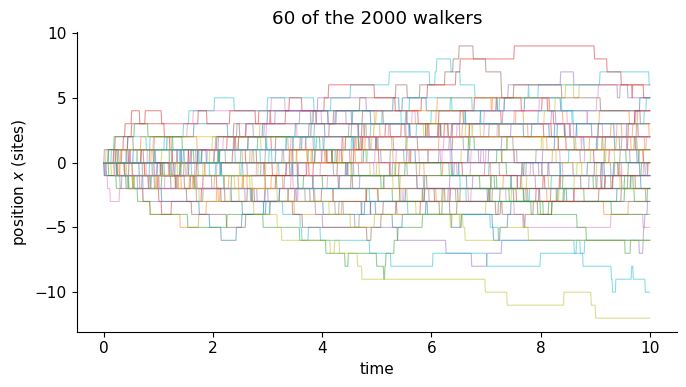

In [4]:
n_walkers = 2000
rng = np.random.default_rng(2)
X = random_walk(n_walkers, n_steps, k, dt, a, rng)

fig, ax = plt.subplots(figsize=(7, 4))
for i in range(60):
    ax.plot(t, X[i], lw=0.8, alpha=0.5)
ax.set(xlabel="time", ylabel="position $x$ (sites)", title="60 of the 2000 walkers")
plt.tight_layout(); plt.show()

The cloud spreads, but it stays centred on zero. Two numbers summarise it at each time: the
**mean** position $\langle x\rangle$ (where the cloud is) and the **mean square** position
$\langle x^2\rangle$ (how wide it is). Since $\langle x\rangle = 0$, $\langle x^2\rangle$ is also
the variance of $x$.

### At the board: $\langle x^2\rangle$ from the rules of Lecture 1

The position after $N = t/\Delta t$ steps is a sum of $N$ independent steps:
$x = \Delta x_1 + \Delta x_2 + \dots + \Delta x_N$.

**Step 1: one step.** Average over the three possibilities of the table:

$$
\langle \Delta x\rangle = (+a)\,k\Delta t + (-a)\,k\Delta t + 0\,(1-2k\Delta t) = 0,
\qquad
\langle \Delta x^2\rangle = a^2\,k\Delta t + a^2\,k\Delta t + 0 = 2a^2k\,\Delta t .
$$

So the variance of one step is $2a^2 k\,\Delta t$.

**Step 2: many steps.** For independent random numbers, **the means add and the variances add**.
(This is the rule we used in Lecture 1 for the molecules that go to one daughter cell, a sum of
$N$ independent coin flips.) So

$$
\langle x\rangle = N\cdot 0 = 0,
\qquad
\langle x^2\rangle = N\cdot 2a^2k\,\Delta t = \frac{t}{\Delta t}\,2a^2 k\,\Delta t = 2\,(a^2k)\,t .
$$

**Step 3: give the combination a name.** $\Delta t$ has dropped out: only the product $a^2 k$ is
left. It is called the **diffusion coefficient**,

$$
\boxed{\;D = a^2 k,\qquad \langle x^2\rangle = 2Dt\;}
$$

$D$ has units of length$^2$/time. The mean square distance grows **in proportion to time**, so
the typical distance $\sqrt{\langle x^2\rangle} = \sqrt{2Dt}$ grows like $\sqrt{t}$: to go twice
as far, a diffusing particle needs **four** times as long.

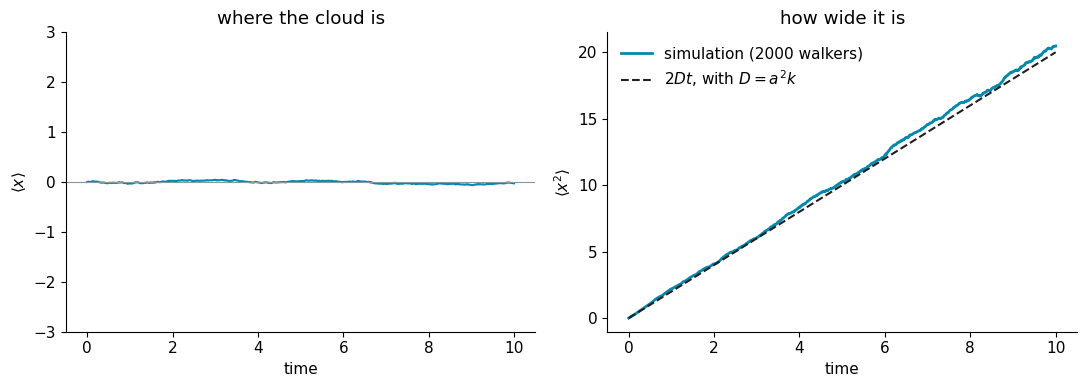

D = a^2 k = 1.000;  slope of <x^2> against t, divided by 2: 1.025


In [5]:
D = a**2 * k
mean_x = X.mean(axis=0)
msd = (X**2).mean(axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(t, mean_x, color=BLUE)
ax1.axhline(0, color=GREY, lw=0.8)
ax1.set(xlabel="time", ylabel=r"$\langle x\rangle$", ylim=(-3, 3), title="where the cloud is")
ax2.plot(t, msd, color=BLUE, lw=2, label="simulation (2000 walkers)")
ax2.plot(t, 2 * D * t, "--", color=INK, label=r"$2Dt$, with $D = a^2k$")
ax2.set(xlabel="time", ylabel=r"$\langle x^2\rangle$", title="how wide it is")
ax2.legend(frameon=False)
plt.tight_layout(); plt.show()

slope = np.polyfit(t, msd, 1)[0]
print(f"D = a^2 k = {D:.3f};  slope of <x^2> against t, divided by 2: {slope / 2:.3f}")

**Try it.** Change `dt` to 0.001 (and `n_steps` to 10000, to reach the same final time) and run
the two cells above again. Does $D$ change? Then change `k` to 2. What happens to $D$, and why?

> **The bootcamp coin, without "stay".** If the particle jumped at every step, left or right with
> probability $1/2$ each, then after $N$ steps with $n_R$ jumps to the right
> $x = a\,n_R - a\,(N-n_R) = a\,(2n_R - N)$. With $n_R$ binomial,
> $\mathrm{Var}(n_R) = N/4$, and the rule $\mathrm{Var}(cX) = c^2\,\mathrm{Var}(X)$ of Lecture 1
> gives $\langle x^2\rangle = 4a^2 \cdot N/4 = Na^2$. It is the same calculation as
> $\langle (n_1-n_2)^2\rangle = N$ for the molecules shared between two daughter cells. Here
> $Na^2 = 2Dt$ with $D = a^2/(2\Delta t)$.

---
## 3. The shape of the cloud

$\langle x^2\rangle$ tells us how wide the cloud is. What about its shape?

**PREDICT.** Sketch the histogram of positions at three times. What shape? How do the height and
the width change when time is multiplied by four?

t = 1: measured width sqrt(<x^2>) = 1.48, sqrt(2Dt) = 1.41
t = 4: measured width sqrt(<x^2>) = 2.88, sqrt(2Dt) = 2.83
t = 9: measured width sqrt(<x^2>) = 4.30, sqrt(2Dt) = 4.24


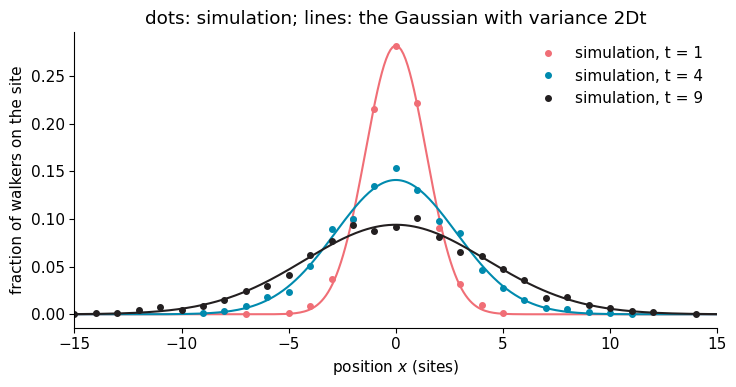

In [6]:
def gaussian(x, D, t):
    return np.exp(-x**2 / (4 * D * t)) / np.sqrt(4 * np.pi * D * t)

fig, ax = plt.subplots(figsize=(7.5, 4))
for t_snap, col in [(1, CORAL), (4, BLUE), (9, INK)]:
    i = int(round(t_snap / dt))
    sites, counts = np.unique(X[:, i], return_counts=True)
    ax.plot(sites, counts / n_walkers, "o", ms=4, color=col, label=f"simulation, t = {t_snap}")
    xx = np.linspace(-15, 15, 300)
    ax.plot(xx, gaussian(xx, D, t_snap) * a, color=col, lw=1.5)
    print(f"t = {t_snap}: measured width sqrt(<x^2>) = {np.sqrt((X[:, i]**2).mean()):.2f}, "
          f"sqrt(2Dt) = {np.sqrt(2 * D * t_snap):.2f}")
ax.set(xlabel="position $x$ (sites)", ylabel="fraction of walkers on the site",
       xlim=(-15, 15), title="dots: simulation; lines: the Gaussian with variance 2Dt")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

The cloud is a **Gaussian** (bell curve) centred on the starting point, with variance $2Dt$:

$$
p(x,t) = \frac{1}{\sqrt{4\pi Dt}}\;e^{-x^2/4Dt}.
$$

From $t = 1$ to $t = 4$ to $t = 9$ the width goes $\sqrt{2}$, $\sqrt{8}$, $\sqrt{18}$: times
four, width times two; times nine, width times three. The area stays 1 (no walker is lost), so as
the bell gets wider it gets lower.

Why a Gaussian? Because $x$ is a sum of many independent steps, and a sum of many independent
random numbers is always close to a Gaussian, whatever the distribution of a single step (the
*central limit theorem*). The binomial of the bootcamp, for large $N$, is the same bell.

### Why we kept "stay put": a trap

Try the walk without the option of staying: jump at every step, $k\,\Delta t = 1/2$.

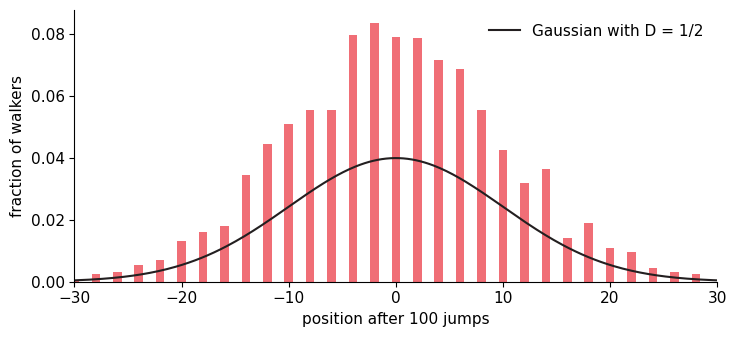

sites occupied after 100 jumps: [-44. -34. -32. -30. -28. -26.] ...


In [7]:
rng = np.random.default_rng(3)
X_coin = random_walk(n_walkers, 100, k=0.5, dt=1.0, a=1.0, rng=rng)   # k dt = 1/2: always jumps
sites, counts = np.unique(X_coin[:, 100], return_counts=True)

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar(sites, counts / n_walkers, width=0.8, color=CORAL)
xx = np.linspace(-30, 30, 300)
ax.plot(xx, gaussian(xx, 0.5, 100), color=INK, label="Gaussian with D = 1/2")
ax.set(xlabel="position after 100 jumps", ylabel="fraction of walkers", xlim=(-30, 30))
ax.legend(frameon=False); plt.tight_layout(); plt.show()
print("sites occupied after 100 jumps:", sites[:6], "...")

Every **odd** site is empty: after an even number of jumps, a particle that always jumps can only
be on an even site. The histogram is a comb, about twice as high as the Gaussian on the even sites
and zero on the odd ones; the Gaussian describes only the average over two neighbouring sites.
Nothing is wrong with the physics: the lattice has left a fingerprint. Letting the particle stay
put, with small jump probabilities, washes this fingerprint out, and is closer to a molecule that
jumps at random *times*, as in the Gillespie algorithm.

### At the board: the diffusion equation

Instead of following walkers, follow the probability $p(x,t)$ that a walker is on site $x$ at
time $t$. To be at $x$ at time $t+\Delta t$, it must have been (PBoC Eq. 13.12):

$$
p(x,t+\Delta t) = \underbrace{(1-2k\Delta t)\,p(x,t)}_{\text{was at }x\text{, stayed}}
+ \underbrace{k\Delta t\,p(x-a,t)}_{\text{was at }x-a\text{, jumped right}}
+ \underbrace{k\Delta t\,p(x+a,t)}_{\text{was at }x+a\text{, jumped left}}.
$$

This is bookkeeping, like the balance between neighbouring states that gave the Poisson
distribution in Lecture 2. Move $p(x,t)$ to the left and divide by $\Delta t$:

$$
\frac{p(x,t+\Delta t)-p(x,t)}{\Delta t} = k\,\big[\,p(x+a,t) - 2p(x,t) + p(x-a,t)\,\big].
$$

The left side is the time derivative when $\Delta t \to 0$. For the bracket, take $a$ small and
expand $p$ around $x$, once for the neighbour on the right ($+a$) and once for the one on the left
($-a$):

$$
p(x+a,t) = p + a\,\frac{\partial p}{\partial x} + \frac{a^2}{2}\,\frac{\partial^2 p}{\partial x^2} + \dots,
\qquad
p(x-a,t) = p - a\,\frac{\partial p}{\partial x} + \frac{a^2}{2}\,\frac{\partial^2 p}{\partial x^2} - \dots
$$

Add the two and subtract $2p(x,t)$: the terms in $p$ cancel, **the first derivatives cancel**
(right and left are equally likely, so there is no preferred direction; Section 6 will see what
happens when they are not), and what is left is the **second derivative**:

$$
p(x+a,t) - 2p(x,t) + p(x-a,t) \simeq a^2\,\frac{\partial^2 p}{\partial x^2}.
$$

In words: the bracket is the slope between $x$ and $x+a$ minus the slope between $x-a$ and $x$,
times $a$, that is, how much the curve bends. With $D = a^2k$:

$$
\boxed{\;\frac{\partial p}{\partial t} = D\,\frac{\partial^2 p}{\partial x^2}\;}
$$

the **diffusion equation**. The Gaussian above is its solution when all walkers start at $x=0$.
Read it as: $p$ goes up where the curve is bent upwards (a dip fills in), and down where it is
bent downwards (a peak flattens). Multiply $p$ by the number of molecules and it describes a
concentration $c(x,t)$: one random walker or many independent ones, same equation.

---
## 4. Diffusion in real units

So far time and length had no units. All that survives from the lattice is $D$; the
microscopic details ($a$, $k$) are invisible at large scales. So to know how diffusion works in a
cell, we need one number: $D$ for a protein.

### Where $D$ comes from: a check with numbers you can estimate

For a sphere of radius $r$ in a liquid of viscosity $\eta$, Einstein's argument (PBoC Section
13.2.5) gives the **Stokes-Einstein relation**

$$
D = \frac{k_BT}{6\pi\eta r},
$$

with $k_BT \approx 4$ pN nm the thermal energy at room temperature. The rules of thumb of PBoC
Table 1.1: water has $\eta \approx 10^{-3}$ Pa s, an "average" protein has radius
$r \approx 2$ nm.

In [8]:
kT = 4e-21            # J (4 pN nm)
eta = 1e-3            # Pa s, water

for name, r in [("protein, r = 2 nm", 2e-9), ("bacterium, r = 1 um", 1e-6)]:
    D_SE = kT / (6 * np.pi * eta * r)          # m^2/s
    print(f"{name:22s}  D in water = {D_SE * 1e12:7.2f} um^2/s")

protein, r = 2 nm       D in water =  106.10 um^2/s
bacterium, r = 1 um     D in water =    0.21 um^2/s


A protein in water: about $100\ \mu$m$^2$/s, the value PBoC uses in Section 13.1.2. Inside a
cell the cytoplasm is crowded with other macromolecules and a protein diffuses more slowly:
PBoC Table 1.1 gives $D \approx 10\ \mu$m$^2$/s for an "average" protein in cytoplasm. We use
that. (Keep the bacterium's own $D$ in mind for Section 6.)

### How long to go a distance $L$?

Turn $\langle x^2\rangle = 2Dt$ around: a diffusing molecule covers a distance $L$ in a time of
order

$$
t \approx \frac{L^2}{2D}.
$$

PBoC writes $L^2/D$; in three dimensions $\langle r^2\rangle = 6Dt$ (each of $x, y, z$ is an
independent walk). These factors of 2 or 6 do not matter for what follows: we are after orders of
magnitude, and the $L^2$ is what matters.

**PREDICT.** A protein crosses an *E. coli* ($\approx 1\ \mu$m) in a time of order a tenth of a
second. How long would it take to diffuse along an axon one metre long (from your spine to your
foot)?

In [9]:
D_cyt = 10.0                                       # um^2/s, protein in cytoplasm (PBoC Table 1.1)
v_motor = 0.2                                      # um/s, molecular motor (PBoC Table 1.1: 200 nm/s)

def nice_time(s):
    for unit, size in [("years", 3.15e7), ("days", 86400), ("hours", 3600), ("min", 60), ("s", 1)]:
        if s >= size:
            return f"{s / size:8.2f} {unit}"
    return f"{s:8.3f} s"

print(f"{'distance':32s} {'diffusion L^2/2D':>18s} {'motor L/v':>16s}")
for name, L in [("across E. coli, 1 um", 1), ("across yeast, 5 um", 5),
                ("across a eukaryotic cell, 20 um", 20), ("1 mm", 1e3), ("an axon, 1 m", 1e6)]:
    print(f"{name:32s} {nice_time(L**2 / (2 * D_cyt)):>18s} {nice_time(L / v_motor):>16s}")

distance                           diffusion L^2/2D        motor L/v
across E. coli, 1 um                        0.050 s           5.00 s
across yeast, 5 um                           1.25 s          25.00 s
across a eukaryotic cell, 20 um             20.00 s         1.67 min
1 mm                                    13.89 hours       1.39 hours
an axon, 1 m                          1587.30 years       57.87 days


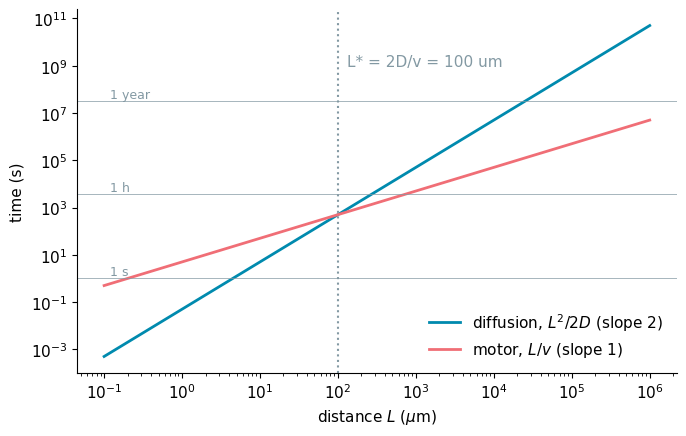

In [10]:
L = np.logspace(-1, 6, 200)                         # um
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(L, L**2 / (2 * D_cyt), color=BLUE, lw=2, label=r"diffusion, $L^2/2D$ (slope 2)")
ax.loglog(L, L / v_motor, color=CORAL, lw=2, label=r"motor, $L/v$ (slope 1)")
L_star = 2 * D_cyt / v_motor
ax.axvline(L_star, color=GREY, ls=":")
ax.text(L_star * 1.3, 1e9, f"L* = 2D/v = {L_star:.0f} um", color=GREY)
for y, lab in [(1, "1 s"), (3600, "1 h"), (3.15e7, "1 year")]:
    ax.axhline(y, color=GREY, lw=0.5); ax.text(0.12, y * 1.4, lab, color=GREY, fontsize=9)
ax.set(xlabel=r"distance $L$ ($\mu$m)", ylabel="time (s)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

Diffusion and a motor cross at $L^* = 2D/v = 100\ \mu$m:

- **below** $L^*$ diffusion is faster than any motor, and free: a bacterium needs no transport
  system at all;
- **above** $L^*$ diffusion loses quadratically: along a metre-long axon it takes more than a
  thousand years, a motor a couple of months. Neurons move cargo with molecular motors (PBoC
  Figure 13.5).

The time grows as $L^2$, the motor's as $L$: whatever the numbers, at long enough distances the
motor always wins, and at short enough distances diffusion always wins.

---
## 5. How long does a transcription factor take to find its site?

In Lecture 2 we wrote $f(X)$, the activity of a promoter as a function of a transcription factor
$X$, by assuming that binding and unbinding are **fast**: the promoter "flickers in seconds while
the protein changes over hours". We never checked the "seconds". Now we can.

### The capture rate

A target (a binding site, a receptor, ...) of size $b$ sits still; molecules of concentration
$c$ diffuse around it with coefficient $D$. Every molecule that touches the target is captured.
How many are captured per second?

**At the board, by dimensions.** The answer can only depend on $D$ (length$^2$/time), $b$
(length) and $c$ (1/length$^3$). The only combination with units of 1/time is $Dbc$. Solving the
diffusion equation in three dimensions around a sphere (PBoC Section 13.3.1, Eq. 13.71) fixes the
number in front:

$$
\boxed{\;\text{captures per unit time} = 4\pi D\,b\,c\;}
$$

Two things to notice:

- it grows with the **size** $b$ of the target, not with its area $b^2$: a target twice as large
  catches only twice as many molecules;
- it is a **rate constant times a concentration**, $k_{\text{on}}\,c$ with
  $k_{\text{on}} = 4\pi Db$: the mass action of Lecture 2, with $k_{\text{on}}$ now computed from
  physics. No reaction can be faster than this: it is the **diffusion limit**.

### One transcription factor, one site

Take one copy of a transcription factor in an *E. coli*, so $c = 1/V$, with $V \approx 1\ \mu$m$^3$
(PBoC Table 1.1). Its site is a few nanometres; we take $b \approx 2$ nm, the radius of an
"average" protein (same table). Then the mean time to find the site is

$$
\tau = \frac{1}{4\pi D b\, c} = \frac{V}{4\pi D b}.
$$

In [11]:
V = 1.0          # um^3, E. coli (PBoC Table 1.1)
b = 0.002        # um, 2 nm
tau = V / (4 * np.pi * D_cyt * b)
print(f"one transcription factor, one site:  tau = V/(4 pi D b) = {tau:.1f} s")
for n_copies in [10, 100]:
    print(f"{n_copies:4d} copies of the factor:               tau = {tau / n_copies:.2f} s")

# the same number in the units of a chemist
N_A = 6.0e23
k_on = 4 * np.pi * (D_cyt * 1e-12) * (b * 1e-6) * N_A * 1e3    # m^3/s -> L/(mol s)
print(f"\nk_on = 4 pi D b = {k_on:.1e} per molar per second")
c_one = 1 / (N_A * V * 1e-15)                                  # one molecule in 1 um^3, in mol/L
print(f"one molecule in 1 um^3 = {c_one * 1e9:.2f} nM  ->  k_on * c = {k_on * c_one:.2f} per second,"
      f"  1/(k_on c) = {1 / (k_on * c_one):.1f} s")

one transcription factor, one site:  tau = V/(4 pi D b) = 4.0 s
  10 copies of the factor:               tau = 0.40 s
 100 copies of the factor:               tau = 0.04 s

k_on = 4 pi D b = 1.5e+08 per molar per second
one molecule in 1 um^3 = 1.67 nM  ->  k_on * c = 0.25 per second,  1/(k_on c) = 4.0 s


A single transcription factor finds its site in a few seconds; with tens of copies, well under a
second. The cell cycle of *E. coli* is about 3000 s (PBoC Table 1.1), and a stable protein
changes on that time scale (Lecture 1). So the separation of time scales of Lecture 2 holds by
about three orders of magnitude.

Two checks on the units, both from earlier lectures:

- **"One molecule per *E. coli* is about 2 nM"** (PBoC Ch. 2): with $V = 1\ \mu$m$^3$ the
  notebook gets 1.67 nM, and $1/(k_{\text{on}}c)$ gives back the same $\tau$.
- In Lecture 2 we said that a second-order rate constant changes when we count molecules instead
  of concentrations: per pair of molecules the rate is $k_{\text{on}}/V$. That is exactly
  $\tau = V/(4\pi Db)$: in a cell twice as large, the factor needs twice as long to meet its site.

This is the simplest estimate, a search in three dimensions only. A real transcription factor
also spends time stuck loosely on the DNA, sliding along it and falling off again ("facilitated
diffusion"), which changes the number; the order of magnitude, seconds rather than hours, is what
we needed.

### Checking $\tau \propto V$ with a simulation, and why the answer is a rate

A walker on a cubic lattice of $L\times L\times L$ sites (it leaves on one face and comes back on
the opposite one, like a molecule in a box with many identical neighbours) jumps at each step to
one of its six neighbours. One site is the target. We start walkers at random sites and count the
steps until each one first lands on the target.

**PREDICT.** If the volume (number of sites) doubles, what happens to the mean search time? And
what does the histogram of search times look like?

In [12]:
MOVES = np.array([[1, 0, 0], [-1, 0, 0], [0, 1, 0], [0, -1, 0], [0, 0, 1], [0, 0, -1]])

def search_times(L, n_walkers, rng):
    '''Steps taken by each walker to first reach the target site (0,0,0) in an L x L x L box.'''
    pos = rng.integers(0, L, size=(n_walkers, 3))
    on_target = (pos == 0).all(axis=1)
    while on_target.any():                                   # nobody starts on the target
        pos[on_target] = rng.integers(0, L, size=(on_target.sum(), 3))
        on_target = (pos == 0).all(axis=1)
    steps = np.zeros(n_walkers, dtype=int)
    searching = np.ones(n_walkers, dtype=bool)
    n = 0
    while searching.any():
        idx = np.flatnonzero(searching)
        pos[idx] = (pos[idx] + MOVES[rng.integers(0, 6, size=idx.size)]) % L
        n += 1
        steps[idx] = n
        found = (pos[idx] == 0).all(axis=1)
        searching[idx[found]] = False
    return steps

rng = np.random.default_rng(5)
sides = [8, 10, 13, 16]
results = {L: search_times(L, 2000, rng) for L in sides}
print(f"{'L':>3s} {'sites':>6s} {'mean steps':>11s} {'mean / sites':>13s} {'std / mean':>11s}")
for L in sides:
    s = results[L]
    print(f"{L:3d} {L**3:6d} {s.mean():11.0f} {s.mean() / L**3:13.2f} {s.std() / s.mean():11.2f}")

  L  sites  mean steps  mean / sites  std / mean
  8    512         678          1.33        1.00
 10   1000        1417          1.42        1.02
 13   2197        3246          1.48        1.03
 16   4096        5846          1.43        1.02


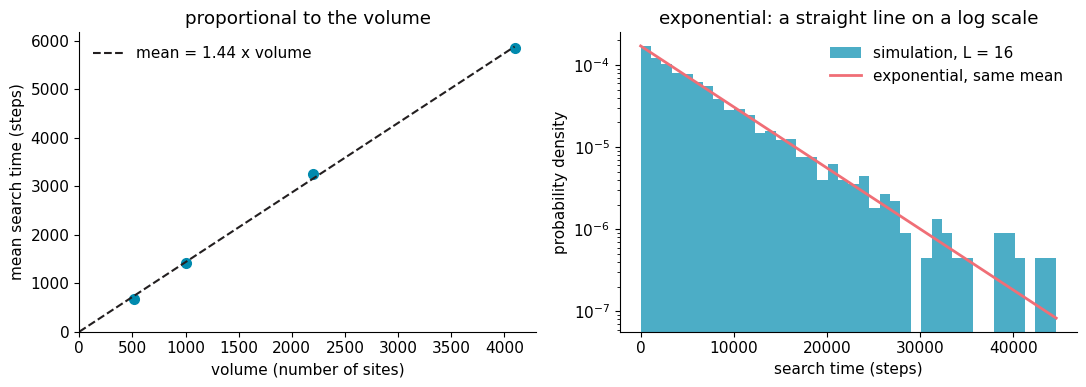

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
n_sites = np.array([L**3 for L in sides])
means = np.array([results[L].mean() for L in sides])
ax1.plot(n_sites, means, "o", color=BLUE, ms=7)
slope = (n_sites @ means) / (n_sites @ n_sites)              # best line through the origin
ax1.plot([0, n_sites.max()], [0, slope * n_sites.max()], "--", color=INK,
         label=f"mean = {slope:.2f} x volume")
ax1.set(xlabel="volume (number of sites)", ylabel="mean search time (steps)", xlim=(0, None),
        ylim=(0, None), title="proportional to the volume")
ax1.legend(frameon=False)

s = results[16]
ax2.hist(s, bins=40, density=True, color=BLUE, alpha=0.7, label="simulation, L = 16")
tt = np.linspace(0, s.max(), 300)
ax2.plot(tt, np.exp(-tt / s.mean()) / s.mean(), color=CORAL, lw=2, label="exponential, same mean")
ax2.set(yscale="log", xlabel="search time (steps)", ylabel="probability density",
        title="exponential: a straight line on a log scale")
ax2.legend(frameon=False)
plt.tight_layout(); plt.show()

Two results:

1. **The mean search time is proportional to the volume**, as $\tau = V/(4\pi Db)$ says.
   (The number in front, about 1.4 steps per site, depends on the lattice; on a lattice the
   target has no sharp size $b$.)
2. **The search times are exponentially distributed**, and their standard deviation equals their
   mean. This is the signature of an event that happens at a **constant rate**, with no memory:
   the same distribution as the waiting times in the Gillespie algorithm, and as the stays in a
   state of the switch in Lecture 4. A walker that has searched for a long time without success
   is no closer to the target than one that has just started: it has wandered off.

This is why we were allowed, from Lecture 2 on, to treat binding as a reaction with a rate
$k_{\text{on}}c$: the random walk of the factor, looked at from the promoter, is a constant
rate of arrivals.

---
## 6. Towards chemotaxis: a random walk with a purpose

An *E. coli* is itself small enough to be knocked about, but it also swims, at about
$20\ \mu$m/s (PBoC Table 1.1). Seen at low magnification its path looks like a random walk; seen
up close it is a series of straight **runs** interrupted by **tumbles**, in which the cell picks
a new direction at random (PBoC Figure 13.3). Three steps take us from there to the question of
the next lecture.

### 6a. A bias gives a drift

Back to the line. Let the rates to the right and to the left differ: $k_R \ne k_L$. The same
calculation as in Section 2 gives

$$
\langle x\rangle = a(k_R - k_L)\,t = v\,t, \qquad
\mathrm{Var}(x) = 2Dt \ \text{ with }\ D = a^2\,\frac{k_R + k_L}{2}.
$$

The cloud moves at a **drift velocity** $v$ and still spreads like a diffusing one.

t = 1: <x> =  0.37 (v t =  0.4),  Var(x) =  1.96 (2 D t =  2.0)
t = 4: <x> =  1.63 (v t =  1.6),  Var(x) =  8.01 (2 D t =  8.0)
t = 9: <x> =  3.55 (v t =  3.6),  Var(x) = 18.09 (2 D t = 18.0)


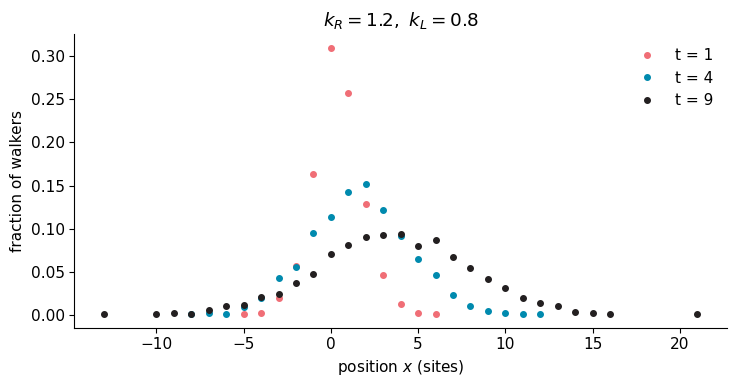

In [14]:
def biased_walk(n_walkers, n_steps, kR, kL, dt, a, rng):
    u = rng.random((n_walkers, n_steps))
    steps = np.where(u < kR * dt, a, np.where(u < (kR + kL) * dt, -a, 0.0))
    x = np.zeros((n_walkers, n_steps + 1))
    x[:, 1:] = np.cumsum(steps, axis=1)
    return x

kR, kL = 1.2, 0.8
rng = np.random.default_rng(6)
Xb = biased_walk(n_walkers, n_steps, kR, kL, dt, a, rng)
v_drift, D_b = a * (kR - kL), a**2 * (kR + kL) / 2

fig, ax = plt.subplots(figsize=(7.5, 4))
for t_snap, col in [(1, CORAL), (4, BLUE), (9, INK)]:
    i = int(round(t_snap / dt))
    sites, counts = np.unique(Xb[:, i], return_counts=True)
    ax.plot(sites, counts / n_walkers, "o", ms=4, color=col, label=f"t = {t_snap}")
    print(f"t = {t_snap}: <x> = {Xb[:, i].mean():5.2f} (v t = {v_drift * t_snap:4.1f}),  "
          f"Var(x) = {Xb[:, i].var():5.2f} (2 D t = {2 * D_b * t_snap:4.1f})")
ax.set(xlabel="position $x$ (sites)", ylabel="fraction of walkers", title=r"$k_R = 1.2,\ k_L = 0.8$")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

The centre moves as $vt$, the width as $\sqrt{2Dt}$. At short times the width wins, at long times
the drift wins: they are equal at a distance of order $2D/v$, the same crossover as diffusion
against a motor in Section 4. **A small bias, given enough time, beats the noise.**

### 6b. Run and tumble is a random walk

Simulate a swimmer in two dimensions: speed $v = 20\ \mu$m/s, and a tumble, with a new random
direction, at rate $\lambda$ = 1 per second (we take "runs of about a second" as a round number).

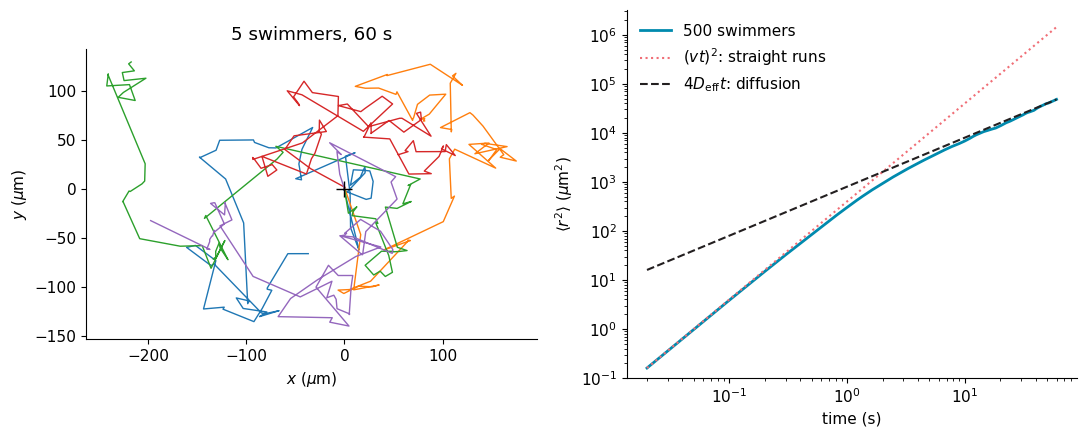

D_eff = v^2/(2 lambda) = 200 um^2/s;  measured <r^2>/(4t) at t = 60 s: 201 um^2/s
for comparison, Brownian D of a 1 um bacterium (Section 4): 0.21 um^2/s


In [15]:
def swimmers(n_cells, T, dt, v, tumble_rate, rng):
    '''2D run-and-tumble. tumble_rate is a function of the swimming angle theta (array).
    Returns positions with shape (n_cells, n_times, 2).'''
    n = int(round(T / dt))
    theta = rng.uniform(0, 2 * np.pi, n_cells)
    pos = np.zeros((n_cells, n + 1, 2))
    for i in range(n):
        pos[:, i + 1, 0] = pos[:, i, 0] + v * np.cos(theta) * dt
        pos[:, i + 1, 1] = pos[:, i, 1] + v * np.sin(theta) * dt
        tumble = rng.random(n_cells) < tumble_rate(theta) * dt
        theta[tumble] = rng.uniform(0, 2 * np.pi, tumble.sum())
    return pos

v_swim, lam, dt_s = 20.0, 1.0, 0.02
rng = np.random.default_rng(7)
P = swimmers(500, 60.0, dt_s, v_swim, lambda th: lam * np.ones_like(th), rng)
ts = np.arange(P.shape[1]) * dt_s
msd2 = (P**2).sum(axis=2).mean(axis=0)
D_eff = v_swim**2 / (2 * lam)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for j in range(5):
    ax1.plot(P[j, :, 0], P[j, :, 1], lw=1)
ax1.plot(0, 0, "k+", ms=12)
ax1.set(xlabel=r"$x$ ($\mu$m)", ylabel=r"$y$ ($\mu$m)", title="5 swimmers, 60 s", aspect="equal")
ax2.loglog(ts[1:], msd2[1:], color=BLUE, lw=2, label="500 swimmers")
ax2.loglog(ts[1:], (v_swim * ts[1:])**2, ":", color=CORAL, label=r"$(vt)^2$: straight runs")
ax2.loglog(ts[1:], 4 * D_eff * ts[1:], "--", color=INK, label=r"$4D_{\rm eff}t$: diffusion")
ax2.set(xlabel="time (s)", ylabel=r"$\langle r^2\rangle$ ($\mu$m$^2$)", ylim=(1e-1, None))
ax2.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"D_eff = v^2/(2 lambda) = {D_eff:.0f} um^2/s;  "
      f"measured <r^2>/(4t) at t = 60 s: {msd2[-1] / (4 * ts[-1]):.0f} um^2/s")
print(f"for comparison, Brownian D of a 1 um bacterium (Section 4): 0.21 um^2/s")

For times shorter than a run, the swimmer goes straight: $\langle r^2\rangle = (vt)^2$, slope 2
on the log-log plot. For times much longer than a run, the runs are independent steps, and we are
back to a random walk: $\langle r^2\rangle = 4D_{\text{eff}}t$ (in two dimensions), slope 1, with
$D_{\text{eff}} = v^2/(2\lambda)$. (We use that formula without deriving it; the simulation checks
it.) Swimming makes the bacterium a diffuser about a thousand times better than the water would
make it on its own.

### 6c. Tumble less when things get better

Put food on the right: the concentration grows with $x$. A swimmer whose direction $\theta$ points
uphill ($\cos\theta > 0$) sees the concentration go up as it swims. Suppose it then **tumbles
less often**: rate $\lambda/2$ when going up, $\lambda$ when going down. It never chooses a
direction: tumbles still pick directions at random.

**PREDICT.** Does the population move towards the food? How fast, compared to 20 $\mu$m/s?

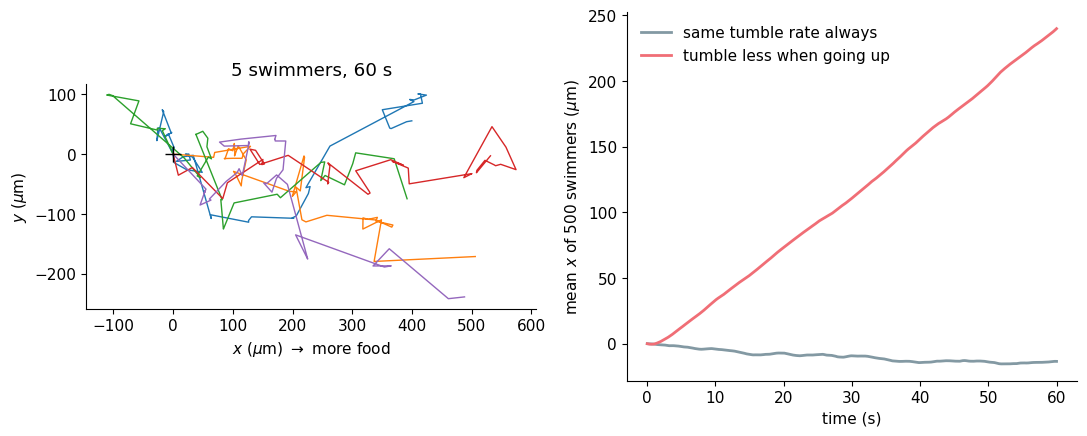

drift velocity towards the food: 4.0 um/s  (swimming speed 20 um/s)


In [16]:
def tumble_less_uphill(theta):
    # theta is the swimming direction of each cell (an array, one angle per cell).
    # The food is on the right, so a cell moves uphill when its x-velocity v cos(theta)
    # is positive, i.e. when cos(theta) > 0.
    # np.where(condition, A, B) gives A where the condition is true and B elsewhere:
    # tumble rate lam/2 for the cells going uphill, lam for the cells going downhill.
    # The function returns one rate per cell; swimmers() uses it at every time step.
    return np.where(np.cos(theta) > 0, lam / 2, lam)

rng = np.random.default_rng(8)
Pc = swimmers(500, 60.0, dt_s, v_swim, tumble_less_uphill, rng)
drift = Pc[:, -1, 0].mean() / 60.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for j in range(5):
    ax1.plot(Pc[j, :, 0], Pc[j, :, 1], lw=1)
ax1.plot(0, 0, "k+", ms=12)
ax1.set(xlabel=r"$x$ ($\mu$m) $\rightarrow$ more food", ylabel=r"$y$ ($\mu$m)",
        title="5 swimmers, 60 s", aspect="equal")
ax2.plot(ts, P[:, :, 0].mean(axis=0), color=GREY, lw=2, label="same tumble rate always")
ax2.plot(ts, Pc[:, :, 0].mean(axis=0), color=CORAL, lw=2, label="tumble less when going up")
ax2.set(xlabel="time (s)", ylabel=r"mean $x$ of 500 swimmers ($\mu$m)")
ax2.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"drift velocity towards the food: {drift:.1f} um/s  (swimming speed {v_swim:.0f} um/s)")

The population drifts towards the food at a sizeable fraction of the swimming speed, although
no cell ever steers. Longer runs uphill than downhill are a **bias in a random walk** (6a), and a
bias wins at long times.

### The question for the next lecture

We cheated. Our swimmers know $\cos\theta$, the direction they are going. A real bacterium does
not: it is about 1 $\mu$m long, and the difference in concentration between its two ends is tiny.
What it can do is **compare the concentration now with the concentration a few seconds ago**.
That needs a memory of the recent past, and that memory must work whether the food is scarce or
abundant: the cell must respond to *changes*, and get used to any constant level.

This is **adaptation**, and how a network of a few proteins does it exactly is the subject of the
next lecture.

---
### What we did

- A walker that jumps left or right with rate $k$ is a sum of independent steps. Means add and
  variances add, so $\langle x^2\rangle = 2Dt$ with $D = a^2k$: distance grows like $\sqrt{t}$.
- The positions form a **Gaussian** of variance $2Dt$, and its probability obeys the
  **diffusion equation** $\partial_t p = D\,\partial_x^2 p$, obtained from simple bookkeeping.
  Only $D$ survives from the microscopic details.
- With $D \approx 10\ \mu$m$^2$/s, diffusion crosses a bacterium in a fraction of a second and an
  axon in more than a thousand years: below $L^* = 2D/v \approx 100\ \mu$m diffusion beats motors, above
  it motors win.
- Diffusion sets a speed limit for binding, $k_{\text{on}} = 4\pi Db$. A transcription factor
  finds its site in seconds, which justifies the fast-binding assumption of Lecture 2. The search
  time is exponential: diffusion, seen from the target, is a constant **rate**.
- A bias turns diffusion into drift. Bacteria get a bias by tumbling less when things improve,
  which requires comparing the present with the recent past: adaptation, next lecture.